In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from gm.data.mnist import train_loader

from gm.models.flow_matching_model import FlowMatchingModel, train_fmm, sample_fmm
from gm.models.energy_based_model import EnergyBasedModel, train_ebm, sample_ebm
from gm.models.energy_matching_model import EnergyMatchingModel, train_emm, sample_emm

In [2]:
D = 2
N = 1
SEED = 42
DEVICE = 'mps'

steps = 2_000
batch_size = 128
lr = 1e-3

eps_max = 0.05

emm_phase1_steps = 1_000
emm_phase2_steps = 1_000
cd_weight = 1.0

In [3]:
def sample_noise(batch_size, dim=28 * 28):
    return torch.randn(batch_size, dim)

sample_data = lambda batch_size: next(iter(train_loader))[0].view(batch_size, -1)

In [4]:
def plot_losses(losses):
    fig, ax = plt.subplots()

    ax.plot(losses, label="Loss", color="tab:blue", alpha=0.5)
    ws = 10
    smoothed = np.convolve(losses, np.ones(ws)/ws, mode="valid")
    ax.plot(np.arange(ws-1, len(losses)), smoothed, label="Smoothed Loss", color="tab:blue")

    plt.legend()
    plt.grid()
    plt.show()

def plot_samples(x, n_cols=8, figsize_scale=1.2):
    x = x.detach().cpu().view(-1, 28, 28)  # (N, 784) -> (N, 28, 28)
    n = x.shape[0]
    n_cols = min(n_cols, n)
    n_rows = (n + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * figsize_scale, n_rows * figsize_scale))
    axes = axes.flatten() if n > 1 else [axes]

    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(x[i], cmap="gray")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


100%|██████████| 2000/2000 [00:20<00:00, 95.96it/s, Loss=1.15]


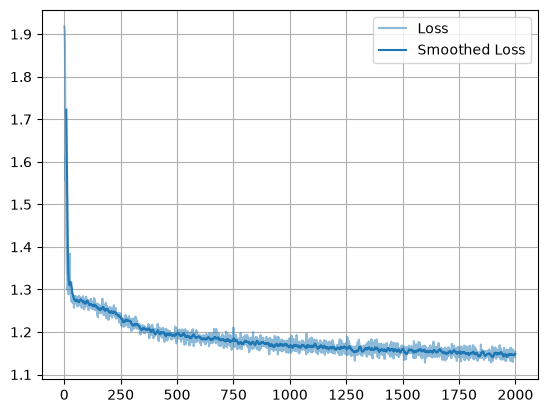

In [5]:
fmm = FlowMatchingModel(dim=784).to(DEVICE)
opt = torch.optim.Adam(fmm.parameters(), lr)
losses = train_fmm(fmm, opt, sample_noise, sample_data, steps, batch_size, DEVICE)
plot_losses(losses)

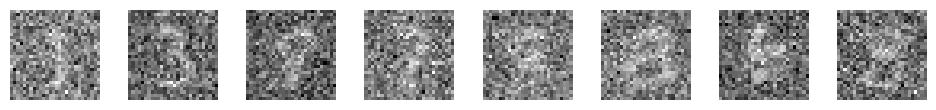

In [6]:
fmm.eval()
x_0 = sample_noise(8).to(DEVICE)
samples = sample_fmm(fmm, x_0, n_steps=1000, device=DEVICE).cpu()
plot_samples(samples)

100%|██████████| 2000/2000 [01:18<00:00, 25.46it/s, Loss=-1999.96]


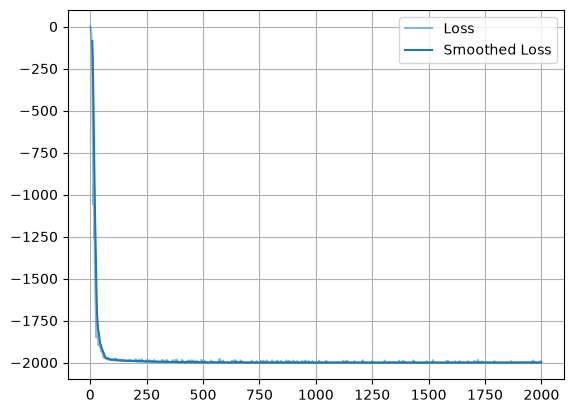

In [7]:
ebm = EnergyBasedModel(dim=784).to(DEVICE)
opt = torch.optim.Adam(ebm.parameters(), lr)
losses = train_ebm(ebm, opt, sample_noise, sample_data, steps, batch_size, eps_max, DEVICE)
plot_losses(losses)


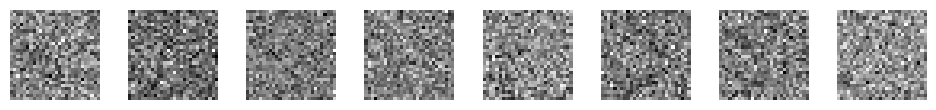

In [8]:
ebm.eval()
x_0 = sample_noise(8).to(DEVICE)
samples = sample_ebm(ebm, x_0, eps_max).cpu()
plot_samples(samples)

100%|██████████| 1000/1000 [00:33<00:00, 29.57it/s, Loss=-69144.04] 


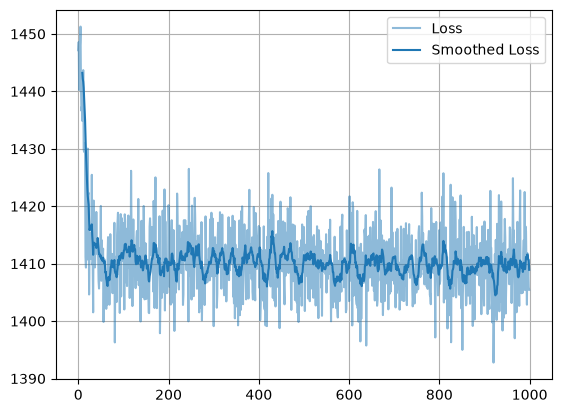

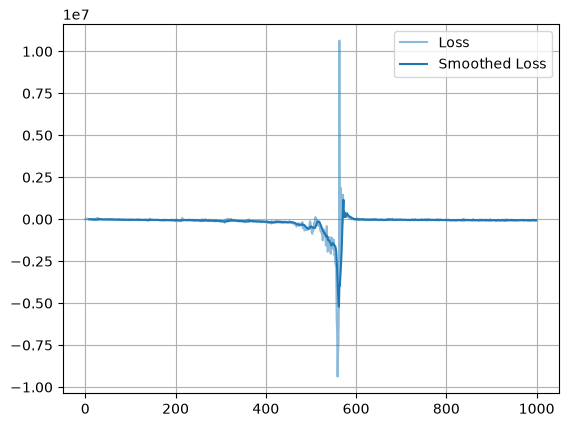

In [9]:
emm = EnergyMatchingModel(dim=784).to(DEVICE)
opt = torch.optim.Adam(emm.parameters(), lr)
p1_losses, p2_losses = train_emm(emm, opt, sample_noise, sample_data, emm_phase1_steps, emm_phase2_steps, batch_size, eps_max, cd_weight, DEVICE)
plot_losses(p1_losses)
plot_losses(p2_losses)

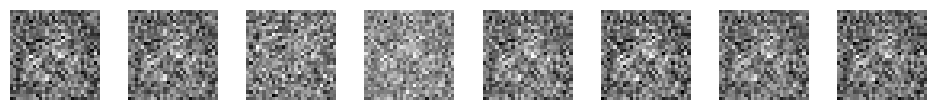

In [10]:
emm.eval()
x_0 = sample_noise(8).to(DEVICE)
samples = sample_emm(emm, x_0, ode_steps=50, langevin_steps=50, eps_max=eps_max).cpu()
plot_samples(samples)